# Lab 4- Eye detection and tracking


Eye detection works similarly to face detection. Instead of using a face cascade file, we will use an eye cascade file.

## Using Haar cascades for object detection

We will be using Haar cascades to detect faces in the example video. Haar cascades, in this case, refers to cascade classifiers based on Haar features. *Paul Viola* and *Michael Jones* first came up with this object detection method in their landmark research paper in 2001. You can check it out here https://www.cs.cmu.edu/~efros/courses/LBMV07/Papers/viola-cvpr-01.pdf

In [ ]:
#import cv2
#import numpy as np

#print("OpenCV:", cv2.__version__)
#print("NumPy:", np.__version__)
#print("Haar cascades:", cv2.data.haarcascades)

Faces detected: 1
Saved result as: detected.jpg


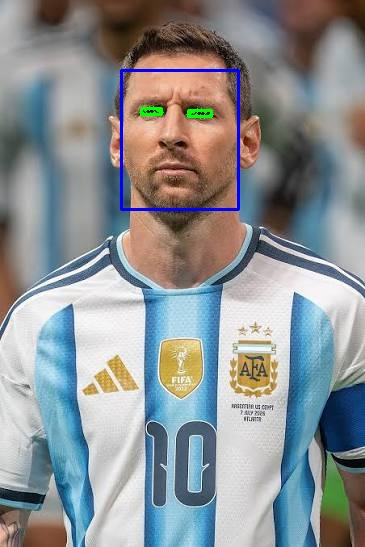

In [1]:
# Install MediaPipe if needed
#!pip install mediapipe

import cv2
import mediapipe as mp #MediaPipe is Google's framework for computer vision. using Face Mesh model.
from IPython.display import display, Image

# ==========================================
# 1. Load image
# ==========================================
#img = a large array containing all the pixels.
img = cv2.imread("messi.jpg")

if img is None:
    raise FileNotFoundError("Could not find 'messi.jpg'")

# MediaPipe expects RGB; Converting BGR → RGB: OpenCV normally stores color images as: BGR
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# ==========================================
# 2. Initialize MediaPipe Face Mesh
# ==========================================

mp_face_mesh = mp.solutions.face_mesh #accesses MediaPipe's Face Mesh functionality.

#creates the actual Face Mesh detector
face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=True, # Tells MediaPipe that process individual still images rather than a continuous video.
    max_num_faces=10, #Detect up to 1o faces. we are only interested in one person. max_num_faces=1
    refine_landmarks=True, #asks MediaPipe to provide more detailed facial landmarks, especially around areas such as: eyes, lips, irises
    min_detection_confidence=0.3 #controls how confident MediaPipe needs to be before deciding that it found a face.
)

#A higher value can reduce false detections, but it can also cause difficult faces to be missed.

# ==========================================
# 3. Detect faces and facial landmarks
# ==========================================

results = face_mesh.process(rgb) #Give the image to Mediapipe: here is my RGB image. Analyze it and find the faces and facial landmarks."

if not results.multi_face_landmarks:
    print("No faces detected")
else:
    print("Faces detected:", len(results.multi_face_landmarks))


# ==========================================
# 4. Eye landmark indices that we want to use to describe eyes
# ==========================================

# Left eye
LEFT_EYE = [
    33, 133, 160, 159, 158,
    157, 173, 144, 145, 153
]

# Right eye
RIGHT_EYE = [
    362, 263, 387, 386, 385,
    384, 398, 373, 374, 380
]


# ==========================================
# 5. Draw face and eye landmarks 
# ==========================================
#Only continue if faces were detected

if results.multi_face_landmarks:

    height, width, _ = img.shape #OpenCV color image has a shape like: (height, width, channels). The _ means: We don't care about the third value here.

    for face_landmarks in results.multi_face_landmarks:

        # ----------------------------------
        # Get all face points
        # ----------------------------------

        points = [] #store the pixel coordinates of every facial landmark here.

        #Loop through every landmark

        for landmark in face_landmarks.landmark:

            x = int(landmark.x * width) #This converts MediaPipe's normalized coordinate into an actual image coordinate.
            y = int(landmark.y * height) #This converts MediaPipe's normalized coordinate into an actual image coordinate.

            points.append((x, y)) #coordinate is stored as:(x,y)

        # ----------------------------------
        # Draw face bounding box 
        # ----------------------------------

        xs = [p[0] for p in points]
        ys = [p[1] for p in points]

    #Find the edges of the face
        x_min = max(0, min(xs))
        x_max = min(width - 1, max(xs))
        y_min = max(0, min(ys))
        y_max = min(height - 1, max(ys))
        
#Draw the face rectangle
        cv2.rectangle(
            img,
            (x_min, y_min),
            (x_max, y_max),
            (255, 0, 0),
            2
        )

        # ----------------------------------
        # Draw left eye
        # ----------------------------------
#Extract the left eye landmarks
        left_eye_points = [] #creating an empty list.

        for index in LEFT_EYE:

            x, y = points[index] #gets the actual pixel coordinate.

            left_eye_points.append((x, y)) #Store each eye point and Now we have all the coordinates describing that eye.

    #Draw the eye landmarks
            cv2.circle(
                img, #image to draw on
                (x, y), #location
                2, #radius
                (0, 255, 0), #green
                -1 #fitted circle
            )

        # ----------------------------------
        # Draw right eye
        # ----------------------------------

        right_eye_points = []

        for index in RIGHT_EYE:

            x, y = points[index]

            right_eye_points.append((x, y))

            cv2.circle(
                img,
                (x, y),
                2,
                (0, 255, 0),
                -1
            )

        # ----------------------------------
        # Draw eye bounding boxes
        # ----------------------------------
#Create eye bounding boxes
        for eye_points in [left_eye_points, right_eye_points]:

            eye_x = [p[0] for p in eye_points]
            eye_y = [p[1] for p in eye_points]

    #Get X and Y coordinates
            ex_min = min(eye_x)
            ex_max = max(eye_x)
            ey_min = min(eye_y)
            ey_max = max(eye_y)

            cv2.rectangle(
                img,
                (ex_min, ey_min),
                (ex_max, ey_max),
                (0, 255, 0),
                2
            )


# ==========================================
# 6. Save result
# ==========================================

output_file = "detected.jpg"

cv2.imwrite(output_file, img)

print("Saved result as:", output_file)


# ==========================================
# 7. Display result
# ==========================================

display(Image(filename=output_file))


# ==========================================
# 8. Close MediaPipe
# ==========================================

face_mesh.close()

In [ ]:
#!conda create -n facedetect python=3.11 -y

In [ ]:
#!conda run -n facedetect pip install numpy==1.26.4 opencv-python==4.10.0.84 mediapipe==0.10.21 matplotlib ipykernel

In [ ]:
#!conda run -n facedetect python -m ipykernel install --user --name facedetect --display-name "Python (Face Detection)"

In [ ]:
#import numpy
#import cv2
#import mediapipe

#print("NumPy:", numpy.__version__)
#print("OpenCV:", cv2.__version__)
#print("MediaPipe:", mediapipe.__version__)

In [ ]:
#!which conda
#!conda --version
#!conda info --envs

In [ ]:
#!/opt/conda/bin/conda run -n facedetect pip install \
 #   numpy==1.26.4 \
 #   opencv-python==4.10.0.84 \
 #   mediapipe==0.10.21 \
 #   matplotlib \
 #   ipykernel

In [ ]:
import cv2
import numpy as np

# Load the Haar cascade files for face and eye
face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier('haarcascade_eye.xml')

# Check if the face cascade file has been loaded correctly
if face_cascade.empty():
	raise IOError('Unable to load the face cascade classifier xml file')

# Check if the eye cascade file has been loaded correctly
if eye_cascade.empty():
	raise IOError('Unable to load the eye cascade classifier xml file')

# Initialize the video capture object
cap = cv2.VideoCapture(0)

# Define the scaling factor
ds_factor = 0.5

# Iterate until the user hits the 'Esc' key
while True:
    # Capture the current frame
    _, frame = cap.read()

    # Resize the frame
    frame = cv2.resize(frame, None, fx=ds_factor, fy=ds_factor, interpolation=cv2.INTER_AREA)

    # Convert to grayscale
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Run the face detector on the grayscale image
    faces = face_cascade.detectMultiScale(gray, 1.3, 5)

    # For each face that's detected, run the eye detector
    for (x,y,w,h) in faces:
        # Extract the grayscale face ROI
        roi_gray = gray[y:y+h, x:x+w]

        # Extract the color face ROI
        roi_color = frame[y:y+h, x:x+w]

        # Run the eye detector on the grayscale ROI
        eyes = eye_cascade.detectMultiScale(roi_gray)

        # Draw circles around the eyes
        for (x_eye,y_eye,w_eye,h_eye) in eyes:
            center = (int(x_eye + 0.5*w_eye), int(y_eye + 0.5*h_eye))
            radius = int(0.3 * (w_eye + h_eye))
            color = (0, 255, 0)
            thickness = 3
            cv2.circle(roi_color, center, radius, color, thickness)

    # Display the output
    cv2.imshow('Eye Detector', frame)

    # Check if the user hit the 'Esc' key
    c = cv2.waitKey(1)
    if c == 27:
        break

# Release the video capture object
cap.release()

# Close all the windows
cv2.destroyAllWindows()
    

#### Applications
We could use the technique we learned in this section to add glasses to a character on screen in a movie (or a beard, or a mustache, and so on).

Another application that comes to mind is tracking the eyes of a truck driver and determining the rate at which they are blinking or maybe even if their eyes are closed to see if they are getting tired and asking them – perhaps forcing them – to pull over.

## Excersise




In [ ]:
# Using the example of eye detector, this time you will code a face detector with bounding boxes
#YOUR CODE HERE
